# Sesion 3: Hough y Harris:

En esta sesión se tocaron los temas de la transformada de Hough y el detector de esquinas de Harris. En esta práctica se pondrán a prueba estas técnicas (o al menos su analogía) para la detección temprana de la diabetes mellitus Tipo 2, usando registros tabulares en lugar de imágenes a procesar. Este cuarderno describe el procedimiento y los resultados de la práctica de laboratorio. 

**Nota: Para representar estas técnicas en el proyecto de detección temprana de Diabetes Mellitus Tipo 2, se necesitan procesar los datos de manmera que representen una señal continua a lo largo del tiempo. Para ello, se generará una Función de "Deterioro metabólico" que representará una señal a lo largo de la vida de un "paciente mexicano promedio"**, el objetivo será detectar puntos fuertes de inflexión a la alza sobre la función de deterioro metabólico y de esta manera encontrar edades  de riesgo. 

---
## 1. Analogía de la Transformada de Hough (Votación y Acumulación de Vecindad)
* **Principio en Visión Artificial:** La Transformada de Hough estándar detecta patrones geométricos (como líneas o bordes fragmentados) mapeando los puntos de la imagen a un espacio de parámetros acumulador, donde los elementos individuales emiten "votos" y las intersecciones de alta densidad revelan estructuras globales.
* **Adaptación a la Señal Continua:** Se implementa un mecanismo de **votación por vecindad mediante una ventana deslizante de tamaño $n$**. En lugar de evaluar cada registro de forma aislada —lo cual lo haría vulnerable al ruido de medición—, cada muestra calcula su pendiente local ($\frac{dz}{dx}$) y emite votos proporcionales a su consistencia con el entorno. 
* **Significado clínico:** Detecta llos rangos de edades sobre los cuales el deterioro metabólico se dispara, es decir, indica en qué "zonas" de la vida humana existen grandes cambios en el deterioro metabólico.

---
## 2. Detector de Esquinas de Harris (Gradientes y Zonas de Inflexión)
* **Principio en Visión Artificial:** El operador de Harris identifica esquinas o puntos singulares evaluando la matriz de segundo momento (autocorrelación de gradientes espaciales en múltiples direcciones) mediante el cálculo del determinante y la traza (Respuesta de Harris $R$).
* **Adaptación a la Señal Continua:** Se calcula la derivada de primer y segundo orden de la curva de riesgo metabólico respecto a la edad ($\frac{dz}{dx}$ y $\frac{d^2z}{dx^2}$). 
* **Significado Clínico:** Funciona como un detector ultra-selectivo que señala con precisión milimétrica los **puntos de inflexión estructural**; es decir, los momentos exactos de la vida del paciente donde la tendencia del deterioro metabólico experimenta cambios abruptos en su aceleración o desaceleración.

# 📃 Configuración del Entorno y Sistema de Registro

En este bloque de código se inicializa el entorno de trabajo correspondiente a todo el notebook, 
## Sección 0
---
### 📦 Módulos y Librerías Utilizadas
| Módulo / Librería | Función Principal |
| :--- | :--- |
| **`pandas` / `numpy`** | Carga, manipulación de estructuras tabulares (`DataFrames`) y operaciones vectoriales para el cálculo de combinaciones lineales. |
| **`logging` / `traceback`** | Registro estructurado de eventos, tiempos de ejecución e historial de errores durante el cálculo del score. |
| **`datetime` / `os` / `sys` / `pathlib`** | Manejo de marcas de tiempo, rutas independientes del sistema operativo y finalización segura del script mediante `System.exit()`. |
| **`matplotlib` / `seaborn`** | Generación de visualizaciones avanzadas (curvas sigmoides, histogramas de densidad y formato visual. |
| **`sklearn.preprocessing`** | Transformación de variables continuas (`StandardScaler`) para garantizar la consistencia en la escala en las variables|

### ⚙️ Parámetros Globales y Rutas Dinámicas
* **`COMPUTER_NAME`**: Detecta automáticamente el equipo de ejecución para seleccionar dinámicamente las rutas de los datasets de entrada (`DATA_SOURCE`) y la carpeta de salida correspondiente .
* **`SEED = 32`**: Define la semilla de aleatoriedad de todo el cuaderno para garantizar la reproducibilidad exacta en el muestreo de datos para las visualizaciones.
* **`YEAR = 2021`**: Define el periodo anual de los archivos procesados.

### 📑 Configuración del Sistema de Registro (*Logging*)
1. **Reinicio de Handlers:** Elimina controladores de *log* previos en la raíz de Python para evitar mensajes duplicados en la consola.
2. **Generación del Nombre de Log:** Asigna un nombre dinámico con marca de tiempo al log resultante.
3. **Persistencia Doble:** Configura `log.basicConfig` para redirigir la salida informativa simultáneamente a un archivo codificado en **UTF-8** y a la consola para el análisis y debuggueo (*StreamHandler*).

In [63]:
# ================================================================================
# 📃 Configuración Inicial y Carga de Datos para el nuevo cuaderno (Etapa 3)
# ================================================================================

import pandas as pd
import numpy as np
import logging as log
import datetime as date
import traceback as trace
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import os
import sys as System
from sklearn.preprocessing import StandardScaler


DEBUG = False
COMPUTER_NAME = os.environ.get('COMPUTERNAME', 'DEFAULT_PC')
SAVE_LOGS = True
SAVE_CHARTS = True
CLEAN_LOGS = True
DATE = date.datetime.now().strftime("%Y-%m-%d_%H-%M-%S")
YEAR = 2021
LOG_NAME = f"Vision_Artificial_Sesion_3_Hough_y_Harris_{YEAR}_{DATE}.txt"
SEED=32

# Define Data sources and output for this notebook
if (COMPUTER_NAME == 'PC_ABRAHAM'):    
    DATA_SOURCE = r"D:\Abraham\MyRepos\Maestria\02_Libros_Recursos\Datasets"
    output_dir = Path("D:/Abraham/MyRepos/Maestria/05_Semestres/3er_Semestre/Vision_artificial/Sesion_3/Output")
else:
    DATA_SOURCE = r"D:\Personal\Maestria\02_Libros_Recursos\Datasets"
    output_dir = Path("D:/Personal/Maestria/05_Semestres/3er_Semestre/Vision_artificial/Sesion_3/Output")

# Clean handler to allow delete previous logs
for handler in log.root.handlers[:]:
    log.root.removeHandler(handler)

if CLEAN_LOGS and output_dir.exists():    
    pattern = f"Vision_Artificial_Sesion_3_Hough_y_Harris_{YEAR}_*.txt"
    old_logs = sorted(list(output_dir.glob(pattern)))
    if old_logs:
        print(f"\n🧹'CLEAN_LOGS' activado. Se encontraron {len(old_logs)} log(s) anterior(es).")
        for old_log in old_logs:
            try:
                old_log.unlink()
                print(f"🗑️ Eliminado: {old_log.name}")
            except Exception as e:
                print(f"⚠️ No se pudo eliminar {old_log.name}: {e}")

# Set output Directory for the resultant log_file_str
output_dir.mkdir(parents=True, exist_ok=True)
log_file_str = str(output_dir / LOG_NAME)

# Basic configuration for logger 
log.basicConfig(
    level=log.INFO,
    format='%(asctime)s - %(levelname)s - %(message)s',
    handlers=[
        log.FileHandler(log_file_str, encoding='utf-8'),
        log.StreamHandler()
    ]
)    
logger = log.getLogger()
logger.info("=" * 80)
logger.info(f"🚀 INICIANDO ETAPA DE CÁLCULO DE SCORE DE RIESGO METABÓLICO CONTINUO")
logger.info("=" * 80 + "\n\n")


2026-10-22 14:23:28,925 - INFO - ================================================================================
2026-10-22 14:23:28,926 - INFO - 🚀 INICIANDO ETAPA DE CÁLCULO DE SCORE DE RIESGO METABÓLICO CONTINUO
2026-10-22 14:23:28,927 - INFO - ================================================================================





🧹'CLEAN_LOGS' activado. Se encontraron 1 log(s) anterior(es).
🗑️ Eliminado: Vision_Artificial_Sesion_3_Hough_y_Harris_2021_2026-10-22_13-20-30.txt


# 📃 Carga de Datasets y Construcción de la Señal Continua de Riesgo Metabólico
Previamente, se han preprocesado varios Datasets del hospital Juarez de México que contienen registros de pacientes de cierta Edad, Sexo y comorbilidades registradas en formato CIE-10. Se usaron esos datasets para generar un Macro Dataset y sobre ese Dataset se entrenó un modelo de Regresión lineal de alta confiabilidad que asignó un valor de Beta de la regresión a cada familia de enfermedades. Bajo este modelo, se puede leer el archivo original y asignar una puntuación de Riesgo metabólico a cada registro del Dataset original, para después construir la **__Función de Riesgo Metabólico__**


En esta sección se integran los resultados del modelo de Regresión Logística previamente entrenado para transformar las variables clínicas discretas de cada paciente en un **Índice Continuo de Deterioro Metabólico ($Z$)** y su correspondiente **Probabilidad Sigmoide ($P$)**.

## Sección 1
---
### 🔧 Metodología

1. **Carga y Validación de Archivos:**
   * Busca y lee desde la carpeta de salida (`Output`) o de origen el dataset concatenado de superclases (`1_Concatenar_y_Estandarizar_HJM_Superclasses_2021.csv`) y la tabla de coeficientes exportada (`2_Regresion_logistica_DMT2_HJM_Betas_Comorbilidades_2021.csv`).
   * Valida la existencia de ambos archivos; en caso de ausencia, emite una advertencia en el *log* y detiene la ejecución mediante `System.exit()`.
2. **Estandarización Preservativa de la Edad:**
   * Se crea una copia de trabajo (`df_proc`) para aplicar `StandardScaler` sobre la columna `Edad`, asegurando que el cálculo mantenga la misma escala $Z$-score con la que se entrenó la Regresión Logística.
   * El DataFrame original (`df_orig`) se conserva intacto para no alterar la edad real en años del paciente en el reporte final.
3. **Cálculo de la Combinación Lineal (Score $Z$):**
   * Extrae el **Intercepto ($\beta_0$)** base de la columna `Interceptor` de la tabla de coeficientes.
   * Asocia cada comorbilidad con su coeficiente $\beta_i$ en un diccionario y evalúa la suma ponderada sobre el dataset:
     $$Z_j = \beta_0 + \sum_{i=1}^{n} \beta_i \cdot X_{ij}$$
4. **Transformación Sigmoide a Probabilidad ($P$):**
   * Mapea el predictor lineal $Z$ al rango probabilístico $[0, 1]$ mediante la función sigmoide:
     $$P_j = \frac{1}{1 + e^{-Z_j}}$$
5. **Asignación y Exportación:**
   * Integra los nuevos indicadores `Score_Deterioro_Metabolico_Z` y `Prob_Deterioro_Metabolico_P` al DataFrame original.
   * Registra las estadísticas descriptivas globales ($\mu, \sigma, \min, \max$) en el sistema de *logging* y exporta el archivo `3_Dataset_Con_Score_Deterioro_Metabolico_2021.csv` con formato UTF-8 (`utf-8-sig`)
6. **Visualización de Densidades**
   * Genera dos paneles de distribución (*KDE / Histplot*) segmentados por la presencia de Diabetes Mellitus Tipo 2 (`Diabetes_Mellitus_T2`):
   * **Panel Izquierdo ($Z$):** Muestra la separación en la escala continua Logit entre la población sana (dominio negativo) y la población con deterioro/diagnóstico (dominio positivo).
   * **Panel Derecho ($P$):** Muestra la distribución bimodal de las probabilidades sigmoides estimadas, guardando la figura resultante en formato de alta resolución (300 DPI).



2026-10-22 14:23:28,950 - INFO - -------SECCION 1: Carga de Datasets y Tabla de Betas-------
2026-10-22 14:23:28,954 - INFO - ⌛ Cargando Dataset de Superclases: 1_Concatenar_y_Estandarizar_HJM_Superclasses_2021.csv
2026-10-22 14:23:35,896 - INFO - ✅ Dataset cargado. Dimensiones: 87027 filas x 1184 columnas.
2026-10-22 14:23:35,906 - INFO - ⌛ Cargando Tabla de Betas: 2_Regresion_logistica_DMT2_HJM_Betas_Comorbilidades_2021.csv
2026-10-22 14:23:35,917 - INFO - ✅ Tabla de Betas cargada (1177 coeficientes registrados).
2026-10-22 14:23:37,637 - INFO - ✅ Variable 'Edad' re-estandarizada correctamente con StandardScaler.
2026-10-22 14:23:37,641 - INFO - 📌 Intercepto base (Beta_0): 6.3613
2026-10-22 14:23:38,100 - INFO - ✅ Puntuación ponderada calculada considerando 1177 variables/comorbilidades.
C:\Users\Abrah\AppData\Local\Temp\ipykernel_16124\294017190.py:53: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor

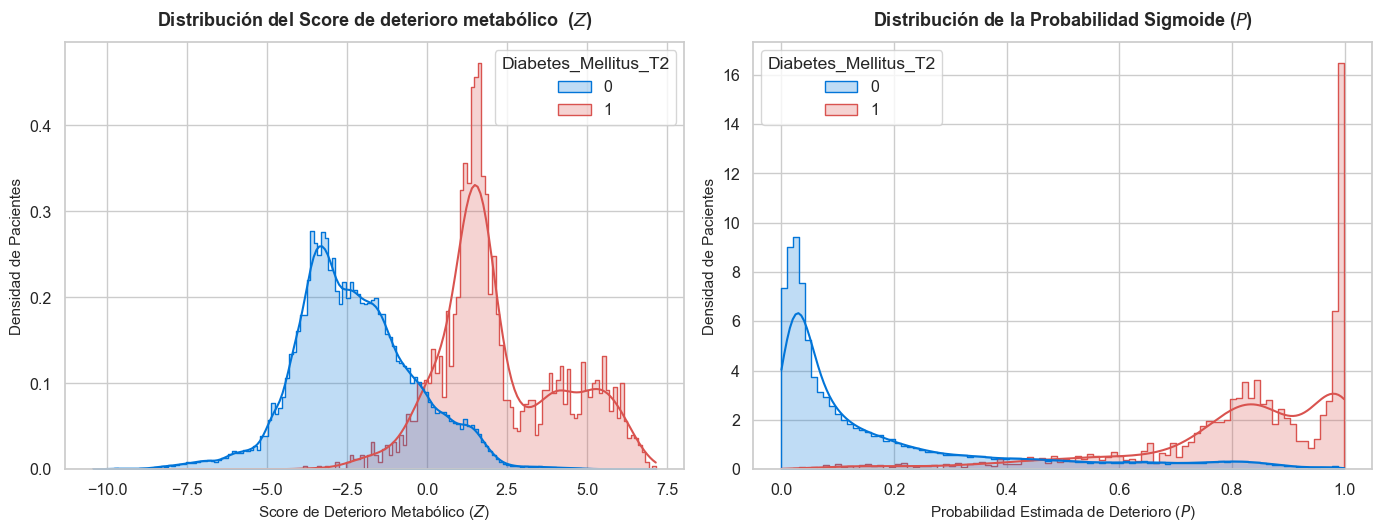

2026-10-22 14:23:40,501 - INFO - ----SECCION 2: Visualización de densidades por clase (FIN)----




In [64]:

try:
    logger.info("-------SECCION 1: Carga de Datasets y Tabla de Betas-------")

    # Given the names from files that should be present in output folder
    file_dataset = f"1_Concatenar_y_Estandarizar_HJM_Superclasses_{YEAR}.csv"
    file_betas = f"2_Regresion_logistica_DMT2_HJM_Betas_Comorbilidades_{YEAR}.csv"
    # Make path variable... DATA_SOURCE is nod used inthis notebook, in that case System.Exit() will be executed
    path_dataset = output_dir / file_dataset if (output_dir / file_dataset).exists() else Path(DATA_SOURCE) / file_dataset
    path_betas = output_dir / file_betas if (output_dir / file_betas).exists() else Path(DATA_SOURCE) / file_betas
    # Warning system to correct input paths
    if not path_dataset.exists():
        logger.warning(f"⚠️ No se encontró el dataset de superclases en: {path_dataset}")
        System.exit()
    if not path_betas.exists():
        logger.warning(f"⚠️ No se encontró la tabla de Betas en: {path_betas}")
        System.exit()

    # Read both files to create dataframes
    logger.info(f"⌛ Cargando Dataset de Superclases: {path_dataset.name}")
    df_orig = pd.read_csv(path_dataset)
    logger.info(f"✅ Dataset cargado. Dimensiones: {df_orig.shape[0]} filas x {df_orig.shape[1]} columnas.")
    logger.info(f"⌛ Cargando Tabla de Betas: {path_betas.name}")
    df_betas = pd.read_csv(path_betas)
    logger.info(f"✅ Tabla de Betas cargada ({len(df_betas)} coeficientes registrados).")

    # "Re-standaraize" the 'Edad' variable in a secure copy
    df_proc = df_orig.copy()
    if 'Edad' in df_proc.columns:
        scaler = StandardScaler()
        df_proc['Edad'] = scaler.fit_transform(df_proc[['Edad']])
        logger.info("✅ Variable 'Edad' re-estandarizada correctamente con StandardScaler.")

    # Map comobidities to beta coefficients 
    beta_dict = dict(zip(df_betas['Comorbilidad / Variable'], df_betas['Beta (Coeficiente)']))
    # Get Intercept (Beta_0) from first row.
    beta_0 = df_betas['Interceptor'][0]         
    logger.info(f"📌 Intercepto base (Beta_0): {beta_0:.4f}")

    # Create "Metabolic degradation score" (Linear combination: Z = Beta_0 + SUM(Beta_i * X_i)) as a linear predictor for each registry
    metabolic_score = np.full(len(df_proc), beta_0, dtype=float)
    comorbidities = 0
    for col, beta in beta_dict.items():
        if col in df_proc.columns:
            # Multiply each applicable beta for all the columns that the registry has enabled, sum the result for get acumulated metabolic score 
            metabolic_score += df_proc[col].fillna(0).values * beta
            comorbidities += 1
    logger.info(f"✅ Puntuación ponderada calculada considerando {comorbidities} variables/comorbilidades.")

    # Transform Sigmoid to Probability  P = 1 / (1 + exp(-Z))
    probabilidad_metabolica = 1.0 / (1.0 + np.exp(-metabolic_score))

    # Assign both indicators to original dataframe Score and probability per registry
    df_orig['Score_Deterioro_Metabolico_Z'] = metabolic_score
    df_orig['Prob_Deterioro_Metabolico_P'] = probabilidad_metabolica
    # Print statistics
    logger.info("📊 Estadísticas de la Señal Continua de Riesgo Metabólico (Z):")
    logger.info(f"   Mínimo: {metabolic_score.min():.4f} | Máximo: {metabolic_score.max():.4f} | Media: {metabolic_score.mean():.4f} | Std: {metabolic_score.std():.4f}")
    # Just keep relevant columns for this practice
    keep_Columns = ['Edad', 'Sex', 'Sex_desc','CIE-10_1_desc','CIE-10_2_desc','CIE-10_3_desc', 'Score_Deterioro_Metabolico_Z','Prob_Deterioro_Metabolico_P','Diabetes_Mellitus_T2']
    # Drop all columns not specified
    df_filtered = df_orig.drop(columns=df_orig.columns.difference(keep_Columns))

    # Export DataSet
    output_scored_path = output_dir / f"3_Dataset_Con_Score_Deterioro_Metabolico_{YEAR}.csv"
    df_filtered.to_csv(output_scored_path, index=False, encoding='utf-8-sig')
    logger.info(f"💾 Dataset guardado exitosamente en: {output_scored_path}")
    logger.info("-------SECCION 1: Carga de Datasets y Tabla de Betas (FIN)-------")

except Exception as e:
    logger.error(f"❌ Error durante la Carga de los datasets, Superclasses y betas: {trace.format_exc()}\n")

try:
    logger.info("-------SECCION 2: Visualización de densidades por clase -------")
    # Se global visualization theme
    sns.set_theme(style="whitegrid", font_scale=1.05)
    # Create 1 Plot with 2 subplots
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
    
    logger.info("📊: Dibujando el Score de deterioro metabólico (Z)")
    # Chart 1: Metabolic degradation score (Z) over Age
    sns.histplot(
        data=df_filtered,
        x='Score_Deterioro_Metabolico_Z',
        hue='Diabetes_Mellitus_T2', # Indicates column class to map
        kde=True,
        element="step",
        stat="density",
        common_norm=False,
        palette=['#0275d8', '#d9534f'], # Color class
        ax=axes[0]      # Draw over left panel 
    )
    axes[0].set_title('Distribución del Score de deterioro metabólico  ($Z$)', fontsize=13, fontweight='bold', pad=12)
    axes[0].set_xlabel('Score de Deterioro Metabólico ($Z$)', fontsize=11)
    axes[0].set_ylabel('Densidad de Pacientes', fontsize=11)

    
    # Just format manipulating...
    # Chart 2: Distribution of probability (P) over Age
    sns.histplot(
        data=df_filtered,
        x='Prob_Deterioro_Metabolico_P',
        hue='Diabetes_Mellitus_T2', # Indicates column class to map
        kde=True,
        element="step",
        stat="density",
        common_norm=False,
        palette=['#0275d8', '#d9534f'], # Color class
        ax=axes[1]      # Draw over right panel 
    )
    
    axes[1].set_title('Distribución de la Probabilidad Sigmoide ($P$)', fontsize=13, fontweight='bold', pad=12)
    axes[1].set_xlabel('Probabilidad Estimada de Deterioro ($P$)', fontsize=11)
    axes[1].set_ylabel('Densidad de Pacientes', fontsize=11)

    plt.tight_layout()
    if SAVE_CHARTS:
        fig_score_path = output_dir / f"3_Construccion_señal_de_Riesgo_Metabolico_HJM_Distribucion_{YEAR}_Fig1.png"
        plt.savefig(fig_score_path, dpi=300, bbox_inches='tight')
        logger.info(f"✅ Gráfica de distribución guardada en: {fig_score_path}")
    plt.show()
    logger.info("----SECCION 2: Visualización de densidades por clase (FIN)----\n\n")
except Exception as e:
    logger.error(f"❌ Error durante la Carga de los datasets, Superclasses y betas: {trace.format_exc()}\n")

# 📃 Análisis de Trayectoria Longitudinal y Punto Crítico de Inflexión por Edad

En este bloque de código se evalúa el comportamiento del **Score Continuo de Deterioro Metabólico ($Z$)** en función de la **Edad del paciente (en años)**, identificando la tendencia promedio de la población, el intervalo de confianza al $95\%$ y la edad exacta de cruce por el umbral neutro de riesgo ($Z = 0.0$).

## Sección 3
---
### 📊 Generación de la función continua de deterioro metabólico.

* **Agrupación por Edad:** Modela los datos agrupando los registros por edad (`df_orig.groupby('Edad')`) y calculando la media (`mean`), desviación estándar (`std`) y número de pacientes (`count`) para cada año.
* **Identificación del Punto Crítico de Inflexión (`edad_cruce`):** Localiza la edad exacta en la que el promedio poblacional se aproxima más a la frontera neutra de riesgo ($Z = 0.0$), determinando la edad epidemiológica promedio en la que la población cruza el umbral de aceleración de riesgo.

### 🎨 Parámetros de la visualización Visualización de la Trayectoria Poblacional

1. **Línea de Tendencia Promedio (`sns.lineplot`):**
   * Traza la curva continua del Score $Z$ a lo largo de la edad con un grosor destacado (`linewidth=1.5`).
   * Incluye la banda sombreada de intervalo de confianza al $95\%$ (`errorbar=('ci', 95)`), reflejando la variabilidad poblacional en cada rango de edad.
2. **Dispersión de Pacientes Reales (`sns.scatterplot`):**
   * Superpone una muestra aleatoria de hasta 2,000 registros (`df_sample`) en el fondo con alta transparencia (`alpha=0.25`) y tamaño reducido (`s=12`).
   * Mantiene la codificación cromática para diferenciar la presencia (`#d9534f`, rojo) o ausencia (`#0275d8`, azul) de Diabetes Mellitus Tipo 2.
3. **Demarcación de Umbrales Críticos:**
   * **Frontera $Z = 0.0$:** Traza una línea horizontal punteada negra (`plt.axhline`) que delimita la zona de baja carga de riesgo ($Z < 0$) de la zona de alto deterioro ($Z > 0$).
   * **Edad Crítica de Cruce:** Dibuja una línea vertical punteada roja (`plt.axvline`) en la edad exacta donde la media poblacional intersecta la frontera neutra, etiquetando dinámicamente el valor en años en la leyenda.
4. **Exportación y Guardado:**
   * Si la bandera `SAVE_CHARTS` está habilitada, guarda la figura en formato de alta resolución (300 DPI) con el nombre `3_Construccion_señal_de_Riesgo_Metabolico_HJM_Señal_Deterioro_2021.png` dentro del directorio `Output`.

2026-10-22 14:23:40,535 - INFO - -------SECCION 3: Obtención de la curva sigmoide -------
2026-10-22 14:23:42,285 - INFO - ✅ Gráfica de trayectoria por edad guardada en: D:\Abraham\MyRepos\Maestria\05_Semestres\3er_Semestre\Vision_artificial\Sesion_3\Output\3_Construccion_señal_de_Riesgo_Metabolico_HJM_Señal_Deterioro_2021.png


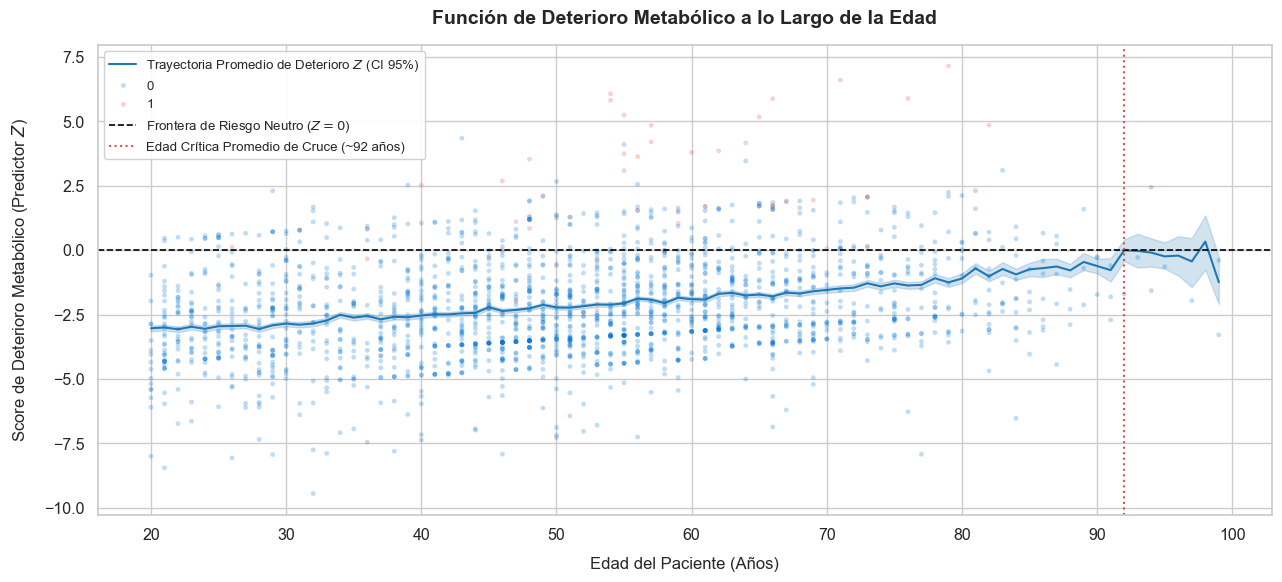

2026-10-22 14:23:42,400 - INFO - --------SECCION 3: Obtención de la curva sigmoide (FIN) -------




In [65]:
try:
    logger.info("-------SECCION 3: Obtención de la curva sigmoide -------")
    # Style configuration 
    sns.set_theme(style="whitegrid", font_scale=1.05)
    plt.figure(figsize=(13, 6))
    # Group 'Edad' and create an auxiliar dataframe to analyze average and variability of Score Z
    df_edad = df_orig.groupby('Edad')['Score_Deterioro_Metabolico_Z'].agg(['mean', 'std', 'count']).reset_index()
    # Chart average trend with dispersion Area (Interval of Conffidence) 
    sns.lineplot(
        data=df_orig,
        x='Edad',
        y='Score_Deterioro_Metabolico_Z',
        color='#1f77b4',
        linewidth=1.5,
        errorbar=('ci', 95),
        label='Trayectoria Promedio de Deterioro $Z$ (CI 95%)'
    )

    # Show individual dots for each registry 
    sns.scatterplot(    
        # Take a random sample of at least 2,000 registries
        data=df_orig.sample(n=min(2000, len(df_orig)), random_state=SEED),
        x='Edad',   
        y='Score_Deterioro_Metabolico_Z',           # Map dots (scattered) of metabolic Risk
        hue='Diabetes_Mellitus_T2',                 # Select class to map
        palette={ 0: '#0275d8', 1: '#d9534f'},   # Select colors to map
        alpha=0.25,                                 # Opacity
        s=12,                                       # Size of the marks
        edgecolor='none'                            # Non edge color
    )

    # Frontier zone horizontal Line (where Z=0)
    plt.axhline(y=0.0, color='black', linestyle='--', linewidth=1.2, label='Frontera de Riesgo Neutro ($Z = 0$)')
    # Identify Average Age where the Z factor is mean=0 (50% risk) 
    critical_age = df_edad.loc[(df_edad['mean'] - 0.0).abs().idxmin(), 'Edad']
    plt.axvline(x=critical_age, color='#d9534f', linestyle=':', linewidth=1.5, 
                label=f'Edad Crítica Promedio de Cruce (~{critical_age:.0f} años)')

    # Tittles and tags
    plt.title('Función de Deterioro Metabólico a lo Largo de la Edad', fontsize=14, fontweight='bold', pad=15)
    plt.xlabel('Edad del Paciente (Años)', fontsize=12, labelpad=10)
    plt.ylabel('Score de Deterioro Metabólico (Predictor $Z$)', fontsize=12, labelpad=10)
    # Legend at the left upper corner
    plt.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9, fontsize=9.5)
    plt.tight_layout()

    if SAVE_CHARTS:
        age_trend_path = output_dir / f"3_Construccion_señal_de_Riesgo_Metabolico_HJM_Señal_Deterioro_{YEAR}.png"
        plt.savefig(age_trend_path, dpi=300, bbox_inches='tight')
        logger.info(f"✅ Gráfica de trayectoria por edad guardada en: {age_trend_path}")

    plt.show()
    logger.info("--------SECCION 3: Obtención de la curva sigmoide (FIN) -------\n\n")

except Exception as e:
    logger.error(f"❌ Error durante la obtención de la curva sigmoide: {trace.format_exc()}\n")

# 📊 Análisis de Eventos Críticos Mediante la Analogía de Hough (Multi-Ventana)
Este bloque de código implementa una adaptación de la **Transformada de Hough** basada en un mecanismo de votación por vecindad y acumulación de evidencia sobre la señal continua de riesgo metabólico. El análisis de la vencindad se hace con diversos rangos de "Ventana" para poder analizar el deterioro metabólico en etapas más cortas o largas de la vida. 

## SECCIÓN 4
---
1. **Preparación y Derivación de la Señal:**
   * Se agrupa el conjunto de datos por edad (`Edad`) calculando la media del score de deterioro (`Score_Deterioro_Metabolico_Z`) para obtener una serie temporal limpia y continua.
   * Se calcula el gradiente global (`np.gradient`) para conocer la tasa de cambio instantánea de la señal en todo el dominio temporal.

2. **Votación por Vecindad (Ventana Deslizante):**
   * Se evalúan múltiples tamaños de ventana (`window_size = [5, 10, 15, 20, 25, 30, 35, 40]`) de forma iterativa en una malla de subgráficos.
   * Para cada posición central `i`, se extrae la vecindad local de pendientes y valores. La fuerza del voto (`vote_strength`) se calcula multiplicando la **media de las pendientes locales** por el **conteo de valores que superan la mediana global** de la señal. Esto garantiza que solo se emitan votos significativos en zonas de tendencia alcista y de alto riesgo.

3. **Normalización Min-Max del Acumulador:**
   * El acumulador de votos se reescala al rango $[0, 1]$ mediante una normalización Min-Max para estandarizar la métrica sin importar el tamaño de la ventana analizada.

4. **Filtrado y Detección por Umbral (`THRESHOLD = 0.65`):**
   * Se identifican como **eventos críticos** aquellos puntos donde la intensidad normalizada del acumulador supera el umbral establecido.

5. **Visualización Comparativa:**
   * Se genera una figura multi-panel (`subplots`), donde cada subgráfico muestra la señal base en gris y los eventos detectados resaltados con un mapa de calor (`YlOrRd`) junto a su respectiva barra de intensidad de votos como referencia. Puntos más rojos en el mapa de calor sufieren una mayor tasa de cambio de la mayoría de vecindades en esa sección

2026-10-22 14:23:42,423 - INFO - ---- SECCION 4: Analogía de Hough con Escala de Eventos ----

2026-10-22 14:23:42,470 - INFO - ⚙️ Procesando análisis de Hough con ventana de tamaño: 5...
2026-10-22 14:23:42,517 - INFO - ⚙️ Procesando análisis de Hough con ventana de tamaño: 10...
2026-10-22 14:23:42,552 - INFO - ⚙️ Procesando análisis de Hough con ventana de tamaño: 15...
2026-10-22 14:23:42,584 - INFO - ⚙️ Procesando análisis de Hough con ventana de tamaño: 20...
2026-10-22 14:23:42,626 - INFO - ⚙️ Procesando análisis de Hough con ventana de tamaño: 25...
2026-10-22 14:23:42,664 - INFO - ⚙️ Procesando análisis de Hough con ventana de tamaño: 30...
2026-10-22 14:23:42,698 - INFO - ⚙️ Procesando análisis de Hough con ventana de tamaño: 35...
2026-10-22 14:23:42,733 - INFO - ⚙️ Procesando análisis de Hough con ventana de tamaño: 40...
2026-10-22 14:23:45,364 - INFO - 💾 Figura con escala de color individual guardada en: D:\Abraham\MyRepos\Maestria\05_Semestres\3er_Semestre\Vision_artific

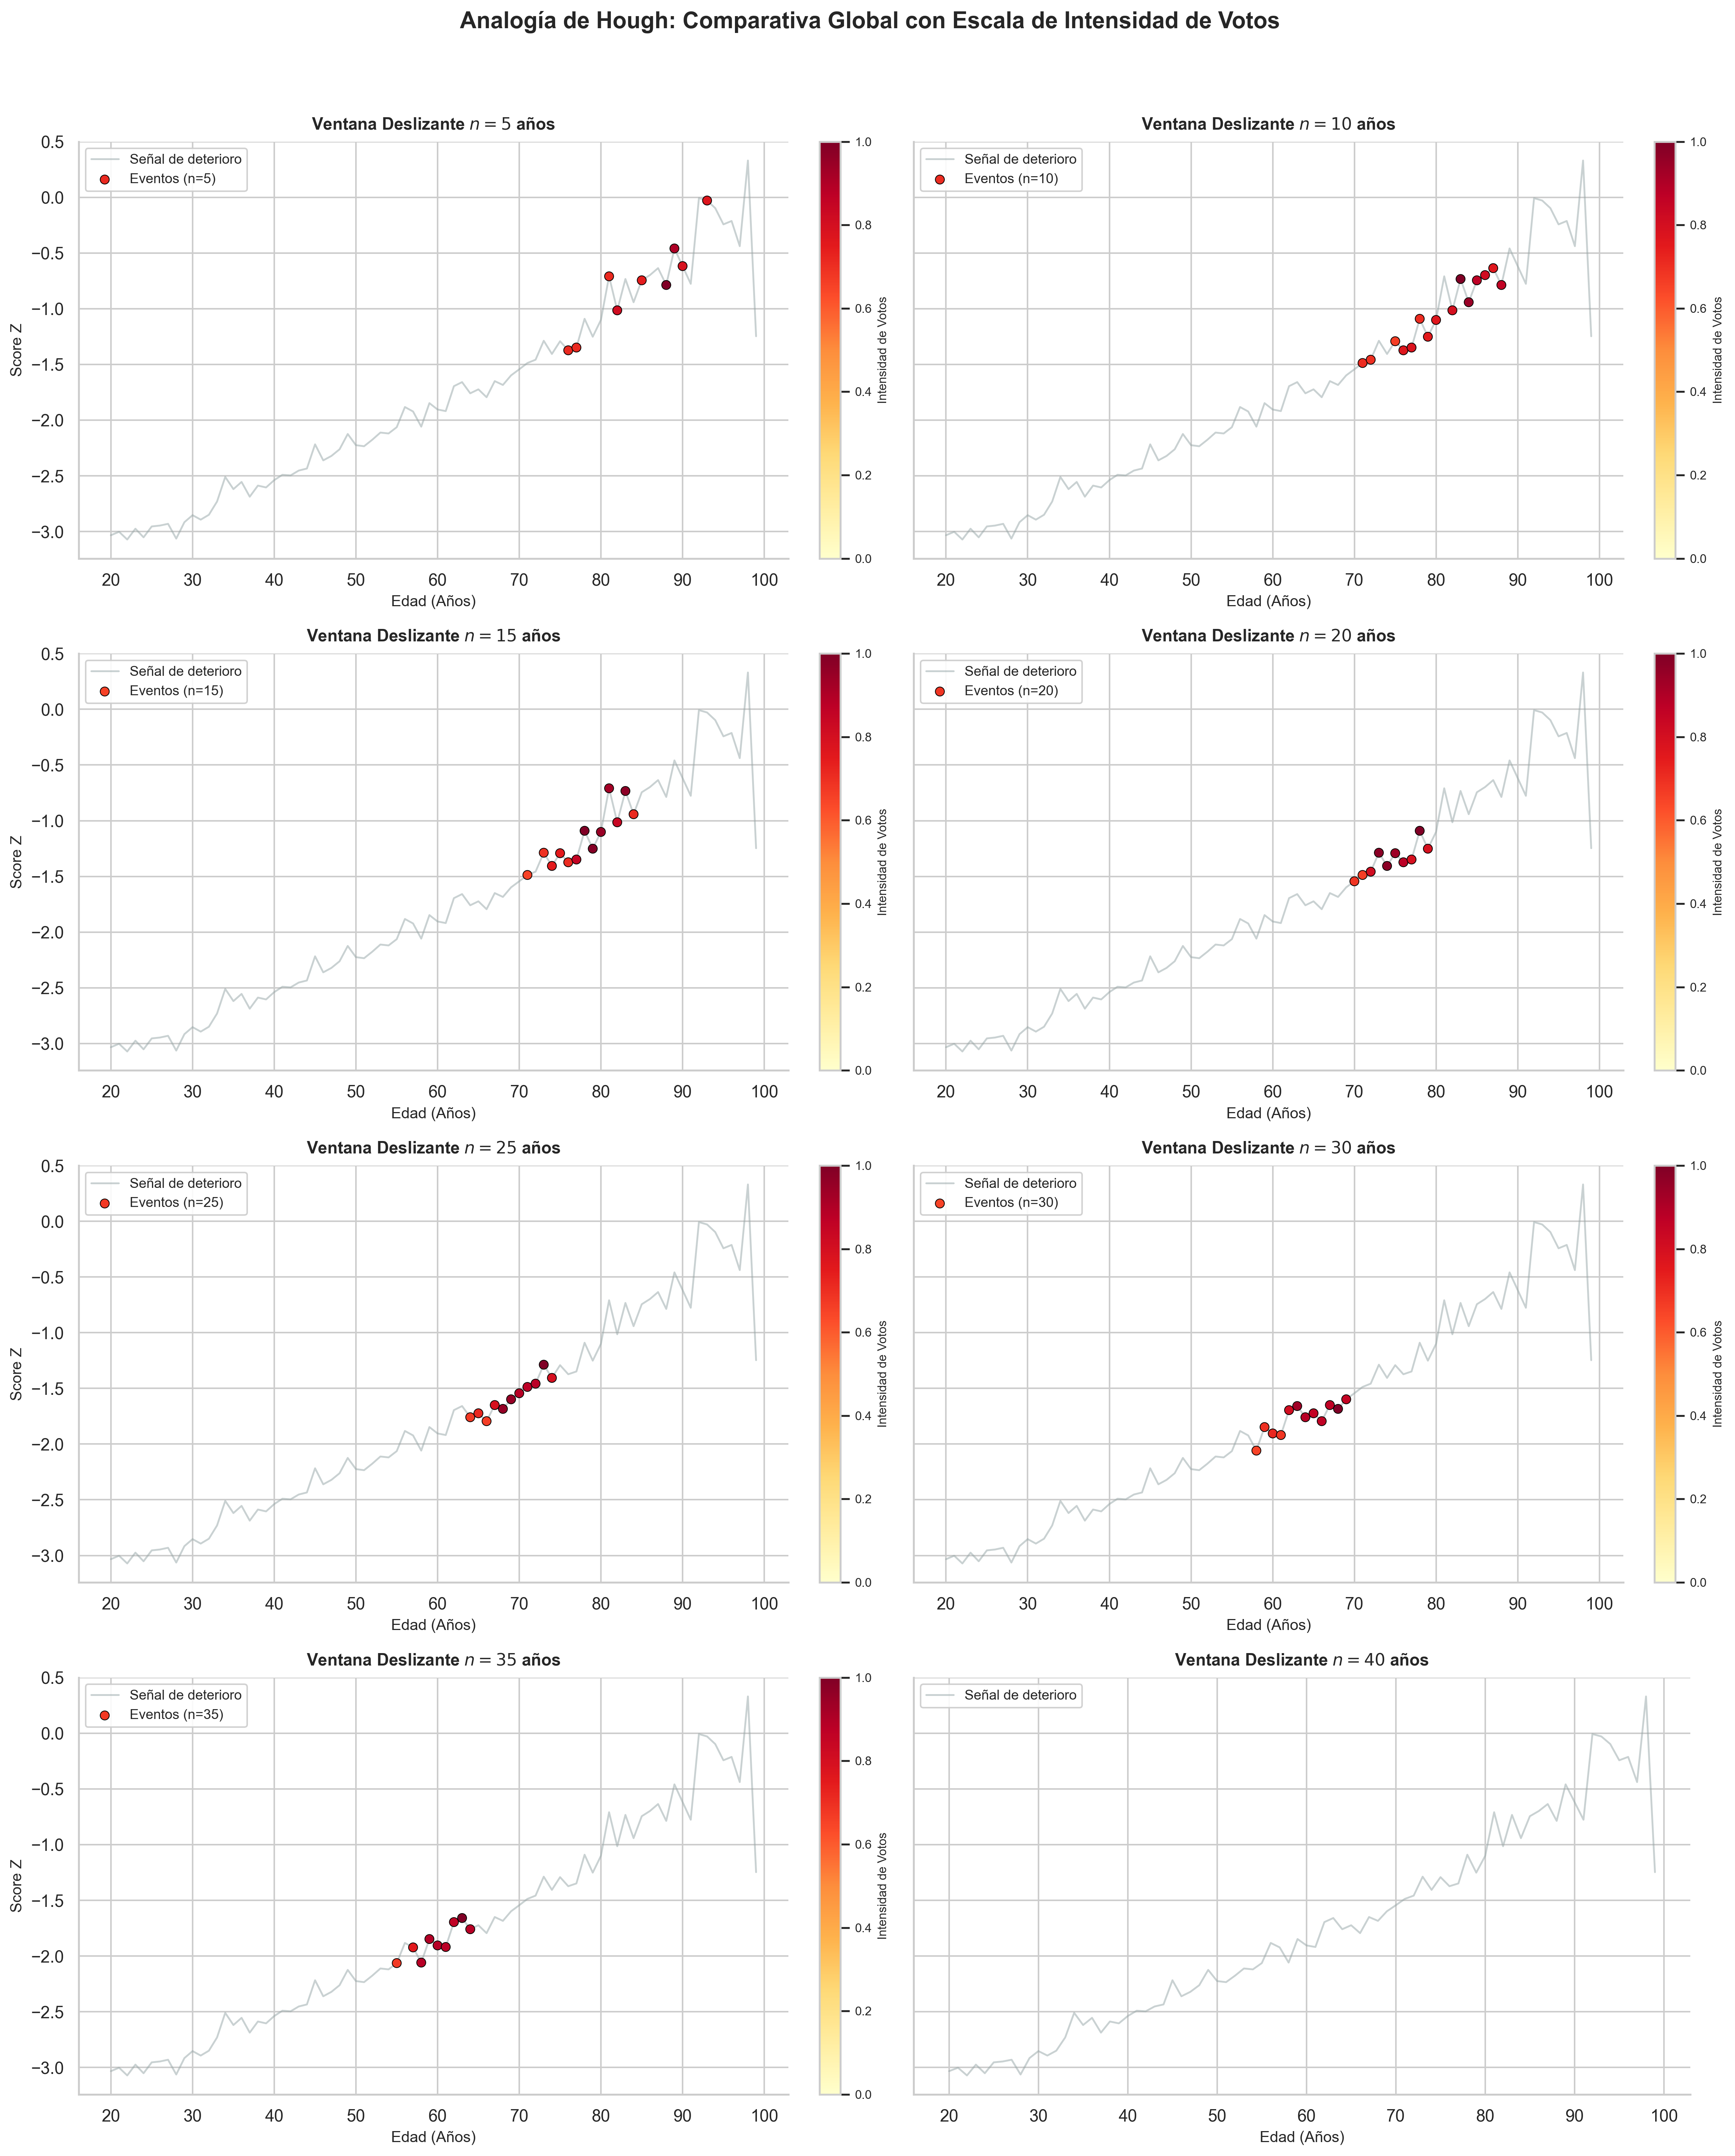

2026-10-22 14:23:46,715 - INFO - ---- SECCION 4: Analogía de Hough con Escala de Eventos (FIN)----



In [66]:
window_size = [5, 10, 15, 20, 25, 30, 35, 40]
THRESHOLD = 0.65

logger.info("---- SECCION 4: Analogía de Hough con Escala de Eventos ----\n")
try:
    # Global data configuration
    sns.set_theme(style="whitegrid", palette="muted")
    # Prepare Data, group (combine registries) by Edad and mean of Metabolic Score degradation
    df_hough_base = df_orig.groupby('Edad')['Score_Deterioro_Metabolico_Z'].mean().reset_index()
    # Remove any other columns and sort by 'Edad' Ascending
    df_hough_base = df_hough_base.sort_values('Edad').dropna()
    # X Axis of the function
    x_edad = df_hough_base['Edad'].values
    # Y Axis of ther function
    z_signal = df_hough_base['Score_Deterioro_Metabolico_Z'].values
    # Slope of the whole Series of X Axis (Edad) according to Y Axis (Score)
    slopes = np.gradient(z_signal, x_edad)

    # Create figure with subplots  2 columns, n rows
    n_rows = int(len(window_size)/2)
    n_cols = int(len(window_size)/n_rows)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 20), dpi=300, sharex=False, sharey=True)
    axes_flat = axes.flatten() # Flatten the array to iterate 


    for idx, w_size in enumerate(window_size):
        ax = axes_flat[idx]
        logger.info(f"⚙️ Procesando análisis de Hough con ventana de tamaño: {w_size}...")
        
        accumulator_votes = np.zeros_like(z_signal)
        for i in range(w_size, len(z_signal) - w_size):
            neighborhood_slopes = slopes[i - w_size : i + w_size]
            neighborhood_values = z_signal[i - w_size : i + w_size]
            
            vote_strength = np.mean(neighborhood_slopes) * np.sum(neighborhood_values > np.median(z_signal))
            accumulator_votes[i] = max(0, vote_strength)

        # Normalization of the acumulator 
        acc_min, acc_max = accumulator_votes.min(), accumulator_votes.max()
        accumulator_norm = (accumulator_votes - acc_min) / (acc_max - acc_min + 1e-8)
        
        events = accumulator_norm > THRESHOLD

        # Base continuous 
        sns.lineplot(
            x=x_edad, y=z_signal, 
            color='#95a5a6', alpha=0.5, linewidth=1.2, 
            label='Señal de deterioro', ax=ax
        )
        
        # Critical points with their own color scale 
        if np.any(events):
            sc = ax.scatter(
                x_edad[events], z_signal[events],
                c=accumulator_norm[events], cmap='YlOrRd',
                vmin=0, vmax=1, s=35, edgecolor='black', linewidth=0.5,
                zorder=5, label=f'Eventos (n={w_size})'
            )
            # Add color bar for refference 
            cbar = fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
            cbar.set_label('Intensidad de Votos', fontsize=8)
            cbar.ax.tick_params(labelsize=8)

        # Tittles and format by subplot 
        ax.set_title(f'Ventana Deslizante $n = {w_size}$ años', fontsize=11, fontweight='bold', pad=8)
        ax.set_xlabel('Edad (Años)', fontsize=10)
        ax.set_ylabel('Score Z', fontsize=10)
        ax.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9, fontsize=9)
        
        sns.despine(ax=ax, top=True, right=True)

    # Overall tittle of the figure 
    fig.suptitle('Analogía de Hough: Comparativa Global con Escala de Intensidad de Votos', fontsize=15, fontweight='bold', y=0.98)
    plt.tight_layout(rect=[0, 0, 1, 0.96])

    if SAVE_CHARTS:
        path_combined = output_dir / f"Hough_Ventanas_Con_Escala_{YEAR}.png"
        plt.savefig(path_combined, dpi=300, bbox_inches='tight')
        logger.info(f"💾 Figura con escala de color individual guardada en: {path_combined}")

    plt.show()
    logger.info("---- SECCION 4: Analogía de Hough con Escala de Eventos (FIN)----\n")

except Exception as e:
    logger.error(f"❌ Error en el análisis de Hough: {e}")

# 📍 Análisis de Puntos de Inflexión Mediante la Analogía de Harris
Este bloque de código adapta el **Detector de Esquinas de Harris** al análisis secuencial de series de tiempo , evaluando múltiples tamaños de ventana local por medio de la segunda derivada

## SECCIÓN 6
---
1. **Preparación y Derivación de la Señal:**
   * Se agrupan los registros por la variable `Edad` y se promedia el score de deterioro metabólico (`Score_Deterioro_Metabolico_Z`) para construir una trayectoria continua.
   * Se calculan analíticamente las derivadas de primer y segundo orden (`dz_dx` y `dz_dx2`).

2. **Matriz de Estructura Local (Analogía de Harris):**
   * Se itera sobre una lista de tamaños de ventana local (`window_sizes = [5, 10, 15, 20, 25, 30, 35, 40]`).
   * Para cada punto central, se construyen los componentes de la matriz de segundo momento (`Ixx`, `Ixy`, `Iyy`) acumulando los gradientes dentro de la vecindad definida por el tamaño de la ventana.
   * Se calcula el determinante (`det_m`), la traza (`trace_m`) y la **Respuesta de Harris ($R$)** utilizando una constante de sensibilidad $k = 0.04$.

3. **Normalización y Filtrado Crítico (`THRESHOLD_HARRIS = 0.65`):**
   * La respuesta cruda de Harris se reescala al intervalo $[0, 1]$ mediante una normalización Min-Max local para cada tamaño de ventana.
   * Se aíslan como **puntos de inflexión crítica** aquellos registros donde la respuesta normalizada supera el umbral estipulado.

4. **Visualización Gráfica Global:**
   * Se genera una figura consolidada estructurada en subgráficos, permitiendo comparar visualmente cómo reacciona el detector de esquinas ante diferentes escalas de vecindad temporal. Cada panel incluye la curva base en tonos neutros y los puntos críticos resaltados mediante un mapa de calor (`plasma`) con su respectiva barra de color.

2026-10-22 14:30:52,780 - INFO - ---- SECCION 5: Analogía de Harris con Escala de Eventos ----

2026-10-22 14:30:52,862 - INFO - ⚙️ Procesando análisis de Harris con ventana de tamaño: 5...
2026-10-22 14:30:52,899 - INFO - ⚙️ Procesando análisis de Harris con ventana de tamaño: 10...
2026-10-22 14:30:52,935 - INFO - ⚙️ Procesando análisis de Harris con ventana de tamaño: 15...
2026-10-22 14:30:52,972 - INFO - ⚙️ Procesando análisis de Harris con ventana de tamaño: 20...
2026-10-22 14:30:53,006 - INFO - ⚙️ Procesando análisis de Harris con ventana de tamaño: 25...
2026-10-22 14:30:53,047 - INFO - ⚙️ Procesando análisis de Harris con ventana de tamaño: 30...
2026-10-22 14:30:53,083 - INFO - ⚙️ Procesando análisis de Harris con ventana de tamaño: 35...
2026-10-22 14:30:53,119 - INFO - ⚙️ Procesando análisis de Harris con ventana de tamaño: 40...
2026-10-22 14:30:55,757 - INFO - 💾 Figura combinada de Harris guardada en: D:\Abraham\MyRepos\Maestria\05_Semestres\3er_Semestre\Vision_artificia

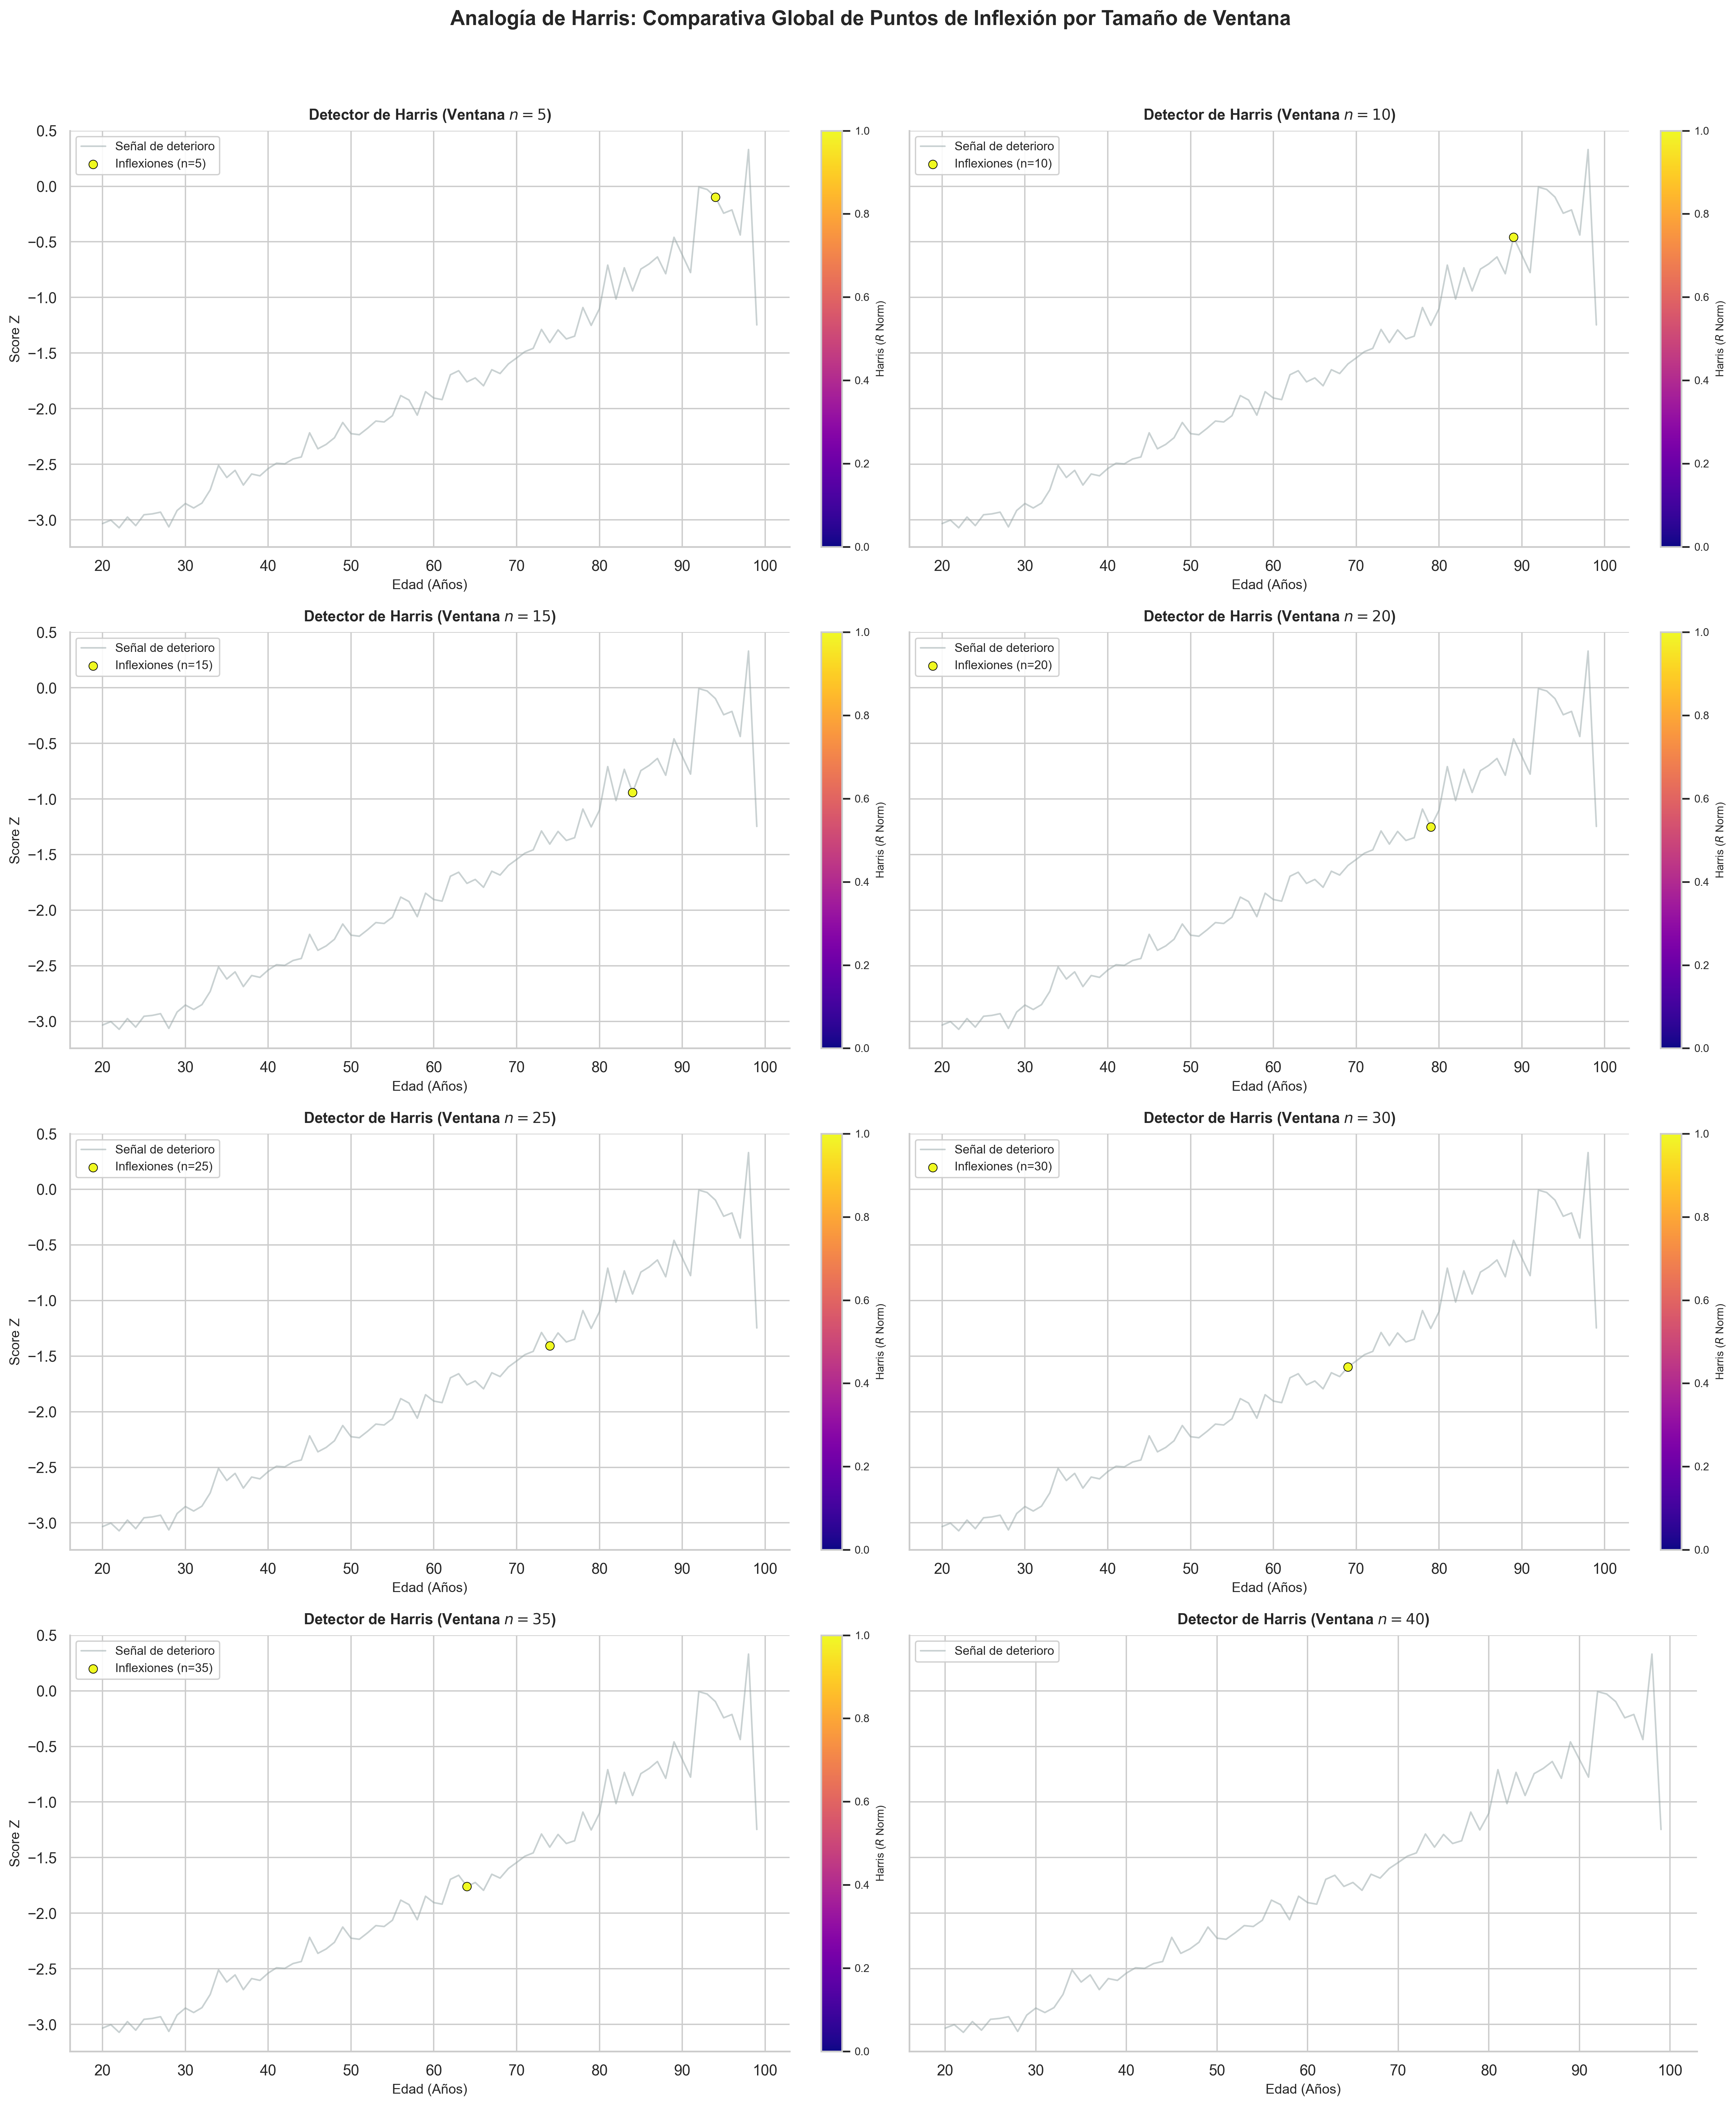

2026-10-22 14:30:57,026 - INFO - ---- SECCION 5: Analogía de Harris con Escala de Eventos (fin) ----



In [ ]:
window_sizes = [5, 10, 15, 20, 25, 30, 35, 40]
THRESHOLD_HARRIS = 0.65  # Harris threshold response 

logger.info("---- SECCION 5: Analogía de Harris con Escala de Eventos ----\n")
try:
    # Global configuration for seaborn 
    sns.set_theme(style="whitegrid", palette="muted")

    # Prepare data by grouping 'Edad'
    df_harris_base = df_orig.groupby('Edad')['Score_Deterioro_Metabolico_Z'].mean().reset_index()
    df_harris_base = df_harris_base.sort_values('Edad').dropna()
    # Get axis to chart
    x_edad = df_harris_base['Edad'].values
    z_signal = df_harris_base['Score_Deterioro_Metabolico_Z'].values

    # Calculate second derivative 
    dz_dx = np.gradient(z_signal, x_edad)
    dz_dx2 = np.gradient(dz_dx, x_edad)

    # Create master figure with subplots (2 columns, 4 rows)
    n_rows = int(len(window_size)/2)
    n_cols = int(len(window_size)/n_rows)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 22), dpi=300, sharex=False, sharey=True)
    axes_flat = axes.flatten() # Flatten array for easy iteration

    # Iterate over each size of Harris window 
    for idx, w_harris in enumerate(window_sizes):
        ax = axes_flat[idx]
        logger.info(f"⚙️ Procesando análisis de Harris con ventana de tamaño: {w_harris}...")
        
        harris_response = np.zeros_like(z_signal)
        k_constant = 0.05   # Empiric parameter, harris sensivity

        # Calculate Harris response for each window
        for i in range(w_harris, len(z_signal) - w_harris):
            # Derivatives
            g_window = dz_dx[i - w_harris : i + w_harris]
            g2_window = dz_dx2[i - w_harris : i + w_harris]
            # Interactions
            Ixx = np.sum(g_window ** 2)
            Ixy = np.sum(g_window * g2_window)
            Iyy = np.sum(g2_window ** 2)
            # Determinant
            det_m = (Ixx * Iyy) - (Ixy ** 2)
            trace_m = Ixx + Iyy
            # Get Harris response
            harris_response[i] = det_m - k_constant * (trace_m ** 2)

        # Normalization of Harris response (0-1) for this window 
        h_min, h_max = harris_response.min(), harris_response.max()
        harris_norm = (harris_response - h_min) / (h_max - h_min + 1e-8)
        
        # Critical points detection based on threshold 
        events_harris = harris_norm > THRESHOLD_HARRIS

        # Draw metabolic degeneration function. 
        sns.lineplot(
            x=x_edad, y=z_signal, 
            color='#95a5a6', alpha=0.5, linewidth=1.2, 
            label='Señal de deterioro', ax=ax
        )
        
        # Draw inflexion points detected
        if np.any(events_harris):
            sc = ax.scatter(
                x_edad[events_harris], z_signal[events_harris],
                c=harris_norm[events_harris], cmap='plasma',
                vmin=0, vmax=1, s=40, edgecolor='black', linewidth=0.5,
                zorder=5, label=f'Inflexiones (n={w_harris})'
            )
            # Colorbar for each subplot 
            cbar = fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
            cbar.set_label('Harris ($R$ Norm)', fontsize=8)
            cbar.ax.tick_params(labelsize=8)

        # Tittles and format 
        ax.set_title(f'Detector de Harris (Ventana $n = {w_harris}$)', fontsize=11, fontweight='bold', pad=8)
        ax.set_xlabel('Edad (Años)', fontsize=10)
        ax.set_ylabel('Score Z', fontsize=10)
        ax.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.9, fontsize=9)
        
        sns.despine(ax=ax, top=True, right=True)

    # The big tittle for the whole figure
    fig.suptitle('Analogía de Harris: Comparativa Global de Puntos de Inflexión por Tamaño de Ventana', fontsize=15, fontweight='bold', y=0.98)
    plt.tight_layout(rect=[0, 0, 1, 0.96])

    if SAVE_CHARTS:
        path_harris_combined = output_dir / f"Harris_Todas_Las_Ventanas_Combinadas_{YEAR}.png"
        plt.savefig(path_harris_combined, dpi=300, bbox_inches='tight')
        logger.info(f"💾 Figura combinada de Harris guardada en: {path_harris_combined}")

    plt.show()
    logger.info("---- SECCION 5: Analogía de Harris con Escala de Eventos (fin) ----\n")

except Exception as e:
    logger.error(f"❌ Error en el análisis de Harris: {e}")